# PaySim — Full transaction-graph system

**Một dataset, một full input, một transaction index, một benchmark.** Notebook này chạy riêng PaySim: Task 1 integrity → Task 2 Degree/PageRank → Task 4 LPA → Task 3 baseline/motif → common point-in-time feature table → 8 factorial ablations + novelty control → validation-frozen test → predictions/model/evidence verification.

Code thuật toán nằm trong `.py`; mỗi cell import đúng hàm của bước đó để Ctrl+click đến source. Không dùng sample làm kết quả full. Các bảng nhỏ là view/aggregate từ full graph, còn mọi account/transaction được lưu trong Parquet ở thư mục run mới.

**Chỉ chạy một workload nặng.** Chọn kernel Windows `.venv` Python 3.12, JDK17; heap 5 GiB/job cap 8 GiB, CPU10%, tối đa 2 logical CPUs và reserve giữ nguyên. Một số bước full có thể lâu; không mở notebook/Spark thứ hai để chạy cùng.


> **STOPPED BY USER — checkpoint 24/10/2026:** đã chạy 8/15 code cells. Dừng trong cell 9, historical snapshot 5/5 (cutoff 355), PageRank mới xong vòng 2/10. Đây là dừng có chủ đích để push checkpoint; runner ghi trạng thái failed vì kernel được đóng, không phải OOM/resource stop. Full validation/test, comparison và gate cuối **chưa nghiệm thu**.
>
> Raw reconciliation, full Degree/PageRank/LPA và motif features đã PASS. Giữ local run `run_20261023T180715049802Z`; snapshots1–4 và blocks0–4 đã có `_SUCCESS`, snapshot5 còn dang dở. Runner hiện chưa tự resume; đọc `agent_job.md` trước khi chạy tiếp. User đã yêu cầu đổi sang CPU budget khoảng90%+ ở lượt tiếp theo; profile này **chưa được cài/kiểm chứng**, code guard hiện vẫn là profile10% lịch sử.


## 1. Môi trường và bảo vệ tài nguyên

Cell khởi tạo kiểm tra native Windows, dependency pins và guard trước Java. Guard từ chối admission thì dừng, không hạ reserve hoặc tự retry.


In [1]:
from pathlib import Path
import sys
from IPython.display import display

repo = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'requirements.txt').exists() and (p / 'src').is_dir())
sys.path.insert(0, str(repo))
from src.motif.presentation import start_system_session
session = start_system_session('paysim')
display(session.runtime)


[RESOURCE] One workload; CPU hard cap 10%; <=2 logical CPUs; job commit cap 8.0 GiB; RAM reserve 7.9 GiB


[RESOURCE] Effective Spark local[2], heap 5120m; spill before increasing RAM


,setting,value
0,dataset,paysim
1,system,Windows
2,python,3.12.10
3,spark,3.5.1
4,graphframes,0.12.2
5,java,17.0.20.1
6,master,local[2]
7,driver_memory,5120m
8,pip_check,PASS
9,cpu_hard_cap_percent,10


## 2. Protocol khai báo trước khi chạy

3 validation folds: train ≤40% / validation (40,50], train ≤50% / validation (50,65], train ≤65% / validation (65,80]. Refit đến 80%, test sau đó; giữ timestamp ties. Snapshot boundaries 20/40/50/65/80%; training rows cũng chỉ dùng snapshot quá khứ. Block đầu chưa có snapshot centrality/community: các feature của hai nhóm này bằng 0 và có unseen flags. Motif vẫn dùng strict-past transactions của từng dòng; các giá trị 0 không phải dự đoán fraud.

8 family factorial là mọi tổ hợp của 3 nhóm graph, luôn có transaction features. Thêm matched-tree transaction+novelty control để tách hiệu ứng cold-start; tổng 9 families. Cùng cây depth=5/min-leaf=50/seed=2026 và class-weight rule. Ngưỡng chọn F1 validation; AP và review budgets 0,1/0,5/1% được báo riêng. Weighted score không phải calibrated probability.


In [2]:
from src.motif.config import FullSystemConfig, SYSTEM_FAMILY_GROUPS

config = FullSystemConfig()
display(config.as_dict())
display(SYSTEM_FAMILY_GROUPS)


{'analysis': {'windows_hours': (24, 168),
  'fold_fractions': (0.4, 0.5, 0.65, 0.8),
  'score_thresholds': (0.001,
   0.005,
   0.01,
   0.02,
   0.05,
   0.1,
   0.2,
   0.3,
   0.5,
   0.7,
   0.9,
   0.99),
  'tree_depth': 5,
  'minimum_leaf_rows': 50,
  'seed': 2026,
  'example_limit': 5,
  'driver_memory': '5g',
  'parallelism': 2},
 'snapshot_fractions': (0.2, 0.4, 0.5, 0.65, 0.8),
 'review_fractions': (0.001, 0.005, 0.01),
 'pagerank_iterations': 10,
 'lpa_iterations': 5,
 'partitions': 64}

{'transaction_only': (),
 'transaction_novelty': ('novelty',),
 'transaction_centrality': ('centrality',),
 'motif_assisted': ('motif',),
 'transaction_community': ('community',),
 'full_fusion': ('centrality', 'motif', 'community'),
 'without_centrality': ('motif', 'community'),
 'without_motifs': ('centrality', 'community'),
 'without_community': ('centrality', 'motif')}

## 3. Full input, integrity và chỉ mục giao dịch chung

Không downsample. `event_id` được tạo một lần cho mỗi physical row rồi persist; duplicate records vẫn là các giao dịch riêng. Các nhánh dùng cùng table này. Output directory được tạo mới, không ghi đè evidence trước. Full vertex metadata/balance chỉ dùng mô tả, không đưa balance cuối kỳ vào detector.


In [3]:
from src.motif.pipeline import start_full_system
from src.motif.presentation import system_protocol_table

run = start_full_system(session.spark, 'paysim', config=config)
display(run.record['integrity'])
display(run.record['support'])
display(system_protocol_table(run))
print('Full run directory:', run.output_dir)


[SYSTEM] Indexed 6,362,620 full transactions once; cutoffs=(135, 206, 239, 303, 355)


{'num_vertices': 9073900,
 'num_edges': 6362620,
 'null_vertices': 0,
 'null_edges': 0,
 'dangling_src': 0,
 'dangling_dst': 0,
 'dangling_edges': 0,
 'self_loops': 0}

{'n': 6362620,
 'unique_ids': 6362620,
 'positives': 8213.0,
 'first_step': 1,
 'last_step': 743}

,time_block,transactions,positives,first_step,last_step,positive_rate
0,0,1292455,1546.0,1,135,0.001196
1,1,1275997,760.0,136,206,0.000596
2,2,618040,399.0,207,239,0.000646
3,3,971880,722.0,240,303,0.000743
4,4,955512,536.0,304,355,0.000561
5,5,1248736,4250.0,356,743,0.003403


Full run directory: D:\Desktop_informations\SGK năm 4\SGK kì 1 năm 4\BigData - Phong\Project_graphX\graphguard-amls-detection\results\full_system\paysim\run_20261023T180715049802Z


### Full raw–Parquet reconciliation
Đối chiếu raw PaySim với toàn bộ Parquet theo hai chiều: mọi edge field và vertex ID/type. Balance cuối giờ có tie không xác định nên không dùng trong detector.


In [4]:
from src.motif.pipeline import full_system_raw_reconciliation

display(full_system_raw_reconciliation(run))


[SYSTEM] raw_reconciliation: PASS


{'status': 'PASS',
 'elapsed_seconds': 150.826,
 'tables': [{'table': 'edges',
   'raw_minus_parquet': 0,
   'parquet_minus_raw': 0,
   'status': 'PASS'},
  {'table': 'vertices_id_type',
   'raw_minus_parquet': 0,
   'parquet_minus_raw': 0,
   'status': 'PASS'}],
 'vertex_balance': 'not compared: equal-hour max_by is ambiguous; never a detector feature',
 'raw_files': [{'path': 'D:\\Desktop_informations\\SGK năm 4\\SGK kì 1 năm 4\\BigData - Phong\\Project_graphX\\graphguard-amls-detection\\data\\raw\\paysim\\PS_20174392719_1491204439457_log.csv',
   'bytes': 493534783,
   'sha256': '16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b'}],
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.0,
  'peak_job_commit_gib': 4.75,
  'minimum_available_ram_gib': 16.61,
  'maximum_host_cpu_percent': 25.9,
  'thermal_sensor': 'CPU temperature unavailable; not a thermal/power hardware guarantee'}}

## 4. Degree và PageRank trên toàn graph

PageRank10/reset=0,15; backend SQL disk-checkpoint đối chiếu independent reference/GraphX trên fixture. Giữ đa cạnh/self-loop, chuẩn hóa cuối để tổng PageRank=N; không gọi score này là xác suất fraud. `account_metrics.parquet` chứa mọi account; top10 và degree plot chỉ là view trình bày.


[SYSTEM] PageRank iteration 1/10 persisted


[SYSTEM] PageRank iteration 2/10 persisted


[SYSTEM] PageRank iteration 3/10 persisted


[SYSTEM] PageRank iteration 4/10 persisted


[SYSTEM] PageRank iteration 5/10 persisted


...

[SYSTEM] PageRank iteration 8/10 persisted


[SYSTEM] PageRank iteration 9/10 persisted


[SYSTEM] PageRank iteration 10/10 persisted


[SYSTEM] centrality_full: PASS


{'status': 'PASS',
 'elapsed_seconds': 330.473,
 'accounts': 9073900,
 'degree_sum': 12725240,
 'rank_sum': 9073899.999602411,
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.0,
  'peak_job_commit_gib': 4.78,
  'minimum_available_ram_gib': 16.61,
  'maximum_host_cpu_percent': 25.9,
  'thermal_sensor': 'CPU temperature unavailable; not a thermal/power hardware guarantee'}}

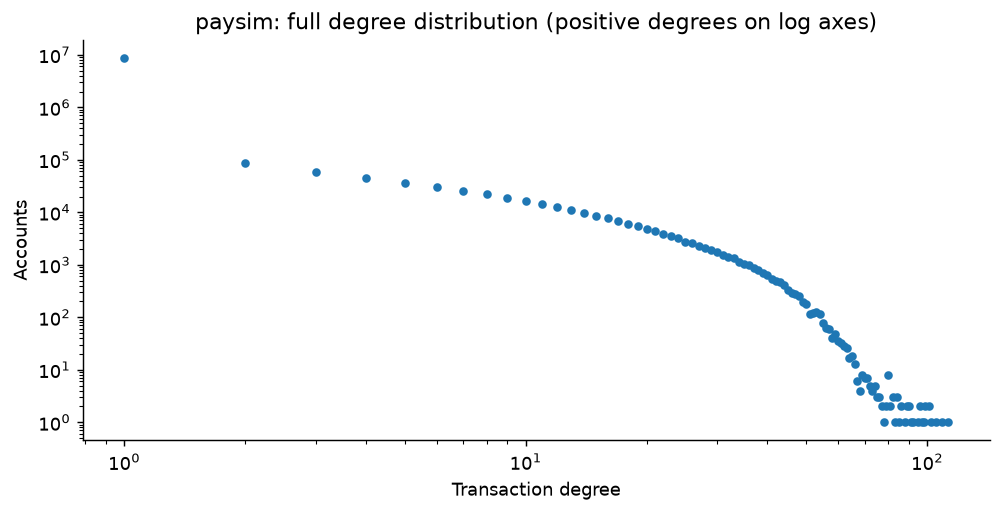

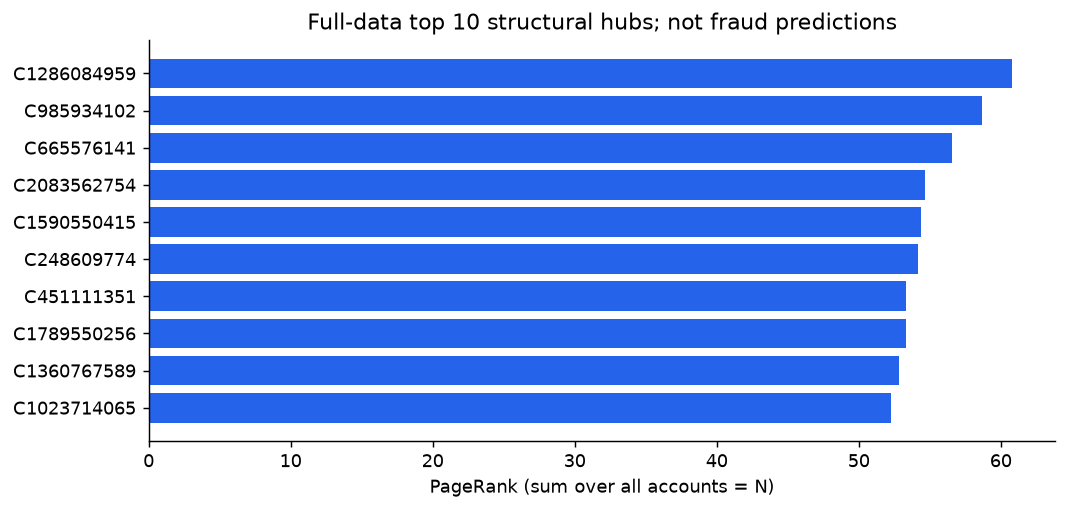

,id,pagerank,inDegree,outDegree,degree
0,C1286084959,60.800382,113,0,113
1,C985934102,58.670332,109,0,109
2,C665576141,56.540283,105,0,105
3,C2083562754,54.676490,102,0,102
4,C1590550415,54.410234,101,0,101
5,C248609774,54.143977,101,0,101
6,C1789550256,53.345209,99,0,99
7,C451111351,53.345209,99,0,99
8,C1360767589,52.812696,98,0,98
9,C1023714065,52.280184,97,0,97


In [5]:
from src.motif.pipeline import full_system_centrality
from src.motif.presentation import plot_system_centrality

display(full_system_centrality(run))
display(plot_system_centrality(run))


## 5. LPA và all-community profiles trên full data

5 vòng modal-neighbor updates, message hai chiều theo mỗi transaction, giữ đa cạnh/self-loop và isolate. Backend SQL dùng seed xxhash64 ổn định, kiểm tra collision và tie chọn nhãn nhỏ nhất; không yêu cầu cùng partition với GraphX khi hòa phiếu. Numeric label không phải fraud class hoặc feature. Assignments/all-summary/amounts theo currency được lưu đầy đủ và đối chiếu SQL độc lập. Fraud statistics ở đây là **posthoc audit**.

Lượt full đã hoàn tất ở run checkpoint này: 5.433.491 communities, internal edges=0 và cross edges=6.362.620; vẫn giữ đủ8.213 fraud labels. Community ID không phải fraud class. Synchronous LPA5 có thể cho phân hoạch với toàn bộ edges là cross; hiệu quả dự đoán phải đọc từ ablation sau khi chạy xong. Không suy ra toàn graph bipartite chỉ từ con số này.


[SYSTEM] LPA iteration 1/5 persisted


[SYSTEM] LPA iteration 2/5 persisted


[SYSTEM] LPA iteration 3/5 persisted


[SYSTEM] LPA iteration 4/5 persisted


[SYSTEM] LPA iteration 5/5 persisted


[SYSTEM] communities_full: PASS


{'status': 'PASS',
 'elapsed_seconds': 720.091,
 'communities': 5433491,
 'accounts': 9073900,
 'transactions': 6362620,
 'positives': 8213,
 'internal_edges': 0,
 'cross_edges': 6362620,
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.0,
  'peak_job_commit_gib': 4.78,
  'minimum_available_ram_gib': 16.61,
  'maximum_host_cpu_percent': 25.9,
  'thermal_sensor': 'CPU temperature unavailable; not a thermal/power hardware guarantee'}}

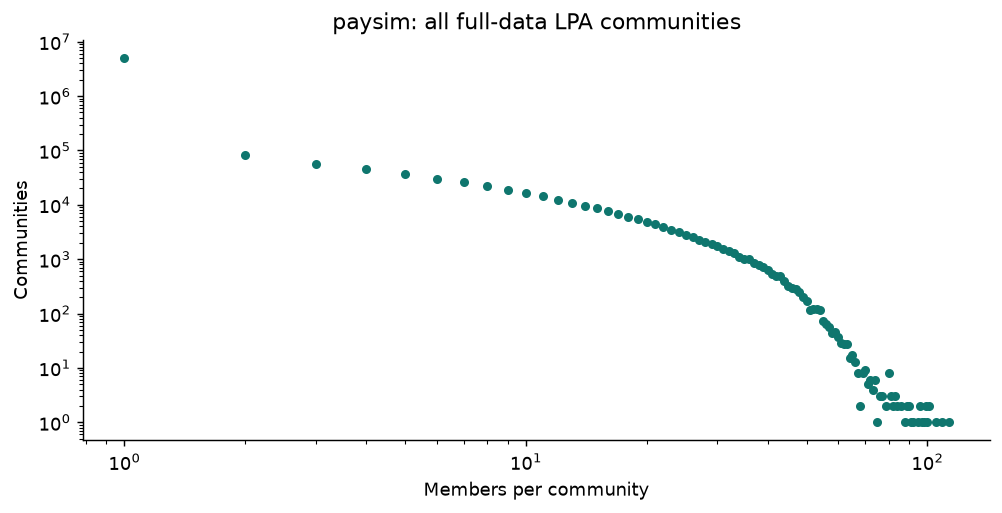

,label,member_count,customer_count,merchant_count,total_tx_count,positive_tx_count,internal_tx_count,cross_tx_count
0,-2869329577538159837,113,113,0,113,0,0,113
1,4492065316503878044,109,109,0,109,0,0,109
2,723737626488219982,105,105,0,105,0,0,105
3,1712382241227080688,101,101,0,101,0,0,101
4,3312339880892662451,101,101,0,101,0,0,101
5,8921025940153633278,100,100,0,100,0,0,100
6,-5988647488635616735,99,99,0,99,0,0,99
7,3936321700822968917,99,99,0,99,0,0,99
8,-8980471668392957081,98,98,0,98,0,0,98
9,2714052426117612431,97,97,0,97,0,0,97


In [6]:
from src.motif.pipeline import full_system_communities
from src.motif.presentation import plot_system_communities

display(full_system_communities(run))
display(plot_system_communities(run))


## 6. Baseline motif theo đề và interpretation boundary

Các query PaySim gốc chạy trên full graph: cycle=0 và relay candidates có thể không có nhãn fraud. Nhãn chỉ được đối chiếu sau query, không là điều kiện tạo inference feature. Bước này không cấp nhãn/feature cho classifier.


In [7]:
from src.motif.pipeline import full_system_baseline

baseline = full_system_baseline(run)
display(baseline.summary)
display(baseline.examples.head(5))


[SYSTEM] motif_baseline: PASS


,dataset,raw_cycles,relay_pairs,same_hour,fraud_transfer_edges,fraud_cashout_edges
0,paysim,0,30,2,0,0


,source_account,middle_account,cashout_account,transfer_step,cashout_step,transfer_amount,cashout_amount,transfer_isFraud,cashout_isFraud
0,C1933517957,C1939958280,C232785081,24,37,265406.49,400729.53,0,0
1,C831358900,C874023329,C1468339976,34,47,1326914.02,292696.43,0,0
2,C1554009922,C874023329,C1468339976,36,47,149467.61,292696.43,0,0
3,C1739712760,C1360393616,C654237876,44,44,161654.47,75989.57,0,0
4,C1483406592,C2013691076,C1228316980,129,132,255345.27,433722.00,0,0


## 7. Causal motif features cho mọi transaction

Fan-in/out, relay, reciprocal, 3-cycle và role-history trong cửa sổ 24/168 giờ. Witness phải trước transaction quyết định; cùng timestamp không giả định thứ tự. Currency/FX được giữ đúng đơn vị. Giao dịch không có motif, self-loop hoặc FX vẫn nằm trong population đánh giá.


In [8]:
from src.motif.pipeline import full_system_motif_features

display(full_system_motif_features(run))


Features: star histories via expiry-prefix sums


Features: reciprocal and same-partner histories


Features: directed topology and chronological cycle evidence


[SYSTEM] motif_features: PASS


{'status': 'PASS',
 'elapsed_seconds': 282.146,
 'rows': 6362620,
 'unique_ids': 6362620,
 'hardware': {'cpu_hard_cap_percent': 10,
  'max_logical_cpus': 2,
  'job_commit_cap_gib': 8.0,
  'peak_job_commit_gib': 5.85,
  'minimum_available_ram_gib': 15.57,
  'maximum_host_cpu_percent': 25.9,
  'thermal_sensor': 'CPU temperature unavailable; not a thermal/power hardware guarantee'}}

## 8. Feature table chung và snapshots quá khứ

Bước này chạy PageRank/LPA trên 5 prefix, không dùng account metrics/community của cuối toàn dataset cho các dòng trước đó. Motif dùng strict-past history; centrality/community có lag snapshot được ghi bằng `snapshot_as_of`. Train/validation/test đều tuân thủ điều kiện as-of < decision. Unknown account được đánh dấu, không tự gọi là fraud.

Đây có thể là bước dài nhất. Mọi row được join đúng một lần, `rows = unique_ids = full transactions`; predicate future snapshot phải bằng 0.

Seen/unseen được xác định tại cutoff snapshot; accounts mới trong block vẫn được giữ đủ rows. Motif có thể dùng các giao dịch trước đó trong block, còn PageRank/LPA giữ lag đã khai báo.


In [9]:
from src.motif.pipeline import full_system_feature_table

display(full_system_feature_table(run))


[SYSTEM] Historical snapshot 1/5, cutoff=135


[SYSTEM] PageRank iteration 1/10 persisted


[SYSTEM] PageRank iteration 2/10 persisted


[SYSTEM] PageRank iteration 3/10 persisted


[SYSTEM] PageRank iteration 4/10 persisted


...

[SYSTEM] LPA iteration 4/5 persisted


[SYSTEM] LPA iteration 5/5 persisted


[SYSTEM] Historical snapshot 5/5, cutoff=355


[SYSTEM] PageRank iteration 1/10 persisted


[SYSTEM] PageRank iteration 2/10 persisted


## 9. Walk-forward và lựa chọn ngưỡng trước test

27 fits = 9 family × 3 folds; preprocessing/class weights chỉ fit từ prefix. Chọn family/threshold bằng mean F1 validation, tie-break worst fold, ít FP và model đơn giản. Không chọn lại sau khi xem test. Nếu không có validation TP thì ABSTAIN.


In [ ]:
from src.motif.pipeline import full_system_validation
from src.motif.presentation import plot_system_validation

leaderboard = full_system_validation(run)
display(leaderboard.head(12))
display(plot_system_validation(run))


## 10. Frozen refit, full test, model export và replay

Mọi family refit đúng cùng prefix đến 80%; mỗi giao dịch test có một score/alert. Truth chỉ join khi fit training hoặc đánh giá. Export predictions cho cả 8 factorial ablations + novelty control, model/scales và TP/FP/FN examples. Reload model được chọn và replay toàn test để kiểm tra score khớp. Test này đã từng được nghiên cứu trong project: **reused internal temporal holdout**, không phải untouched benchmark.


In [ ]:
from src.motif.pipeline import full_system_test

metrics = full_system_test(run)
display(metrics[['model', 'threshold', 'TP', 'FP', 'FN', 'TN',
                 'precision', 'recall', 'F1', 'average_precision',
                 'alert_rate', 'selected_on_validation']])
display(metrics[['model','precision_low95','precision_high95','recall_low95','recall_high95']])


## 11. Đọc kết quả: cùng mẫu số và ngân sách review

Không kết luận fusion tốt hơn chỉ vì đã code/chạy PASS. Đọc baseline và full/drop-group ablations cùng nhau. PR/AP xử lý score ties theo nhóm; review budget chọn đúng K, tie-break content key rồi common event ID, không dùng nhãn. F1-threshold alerts và Top-K review là hai operating policies khác nhau. CI Wilson trong CSV chưa điều chỉnh tương quan account/time.


In [ ]:
from src.motif.presentation import plot_system_results

display(plot_system_results(run))
display(run.record['novelty_baseline'])
display(run.record['selected_test_metrics'])


## 12. Chứng cứ giao dịch thật

Minh họa một test alert/TP của model được validation chọn, nếu có. Graph chỉ vẽ các event thật và witness kiểm tra được; nhãn hiển thị để audit sau dự đoán. Một ví dụ không chứng minh motif gây ra mọi phần cải thiện của model. Nếu ABSTAIN/no TP/no eligible path thì ghi rõ thay vì dựng vòng giả.


In [ ]:
from src.motif.presentation import system_case_evidence

display(system_case_evidence(run))


## 13. Nghiệm thu artifact và publication của run local

Verifier stream predictions và tính lại confusion/AP độc lập, kiểm tra hash của toàn bộ artifacts và full-row coverage. Chỉ khi tất cả phase/source/input/output hợp lệ mới publish latest pointer **ở máy**, không Git push. Performance yếu vẫn phải báo thật; software PASS không thay tiêu chí precision/recall của nghiệp vụ.


In [ ]:
from src.motif.pipeline import finalize_full_system

display(finalize_full_system(run))


## 14. Nguồn code và tài nguyên thực tế

Các hash này là source đã thực thi; sửa code cần run mới. Cell cuối đóng Spark và trả memory measurements. Notebook runner lưu output sau từng cell và đóng kernel/JVM; không khởi chạy notebook còn lại trước khi process này kết thúc.


In [ ]:
from pandas import DataFrame

display(DataFrame(run.record['source_sha256'].items(), columns=['source', 'executed_sha256']))
display(session.close())


## Giới hạn kết luận

Notebook này đánh giá nhãn fraud của PaySim; kết luận được giữ trong đúng dataset này. Không gộp F1 hai dataset, không gọi community là vòng rửa tiền thật, và không coi unalerted là hợp pháp. Cần test ngoài mẫu mới nếu muốn khẳng định khả năng tổng quát hóa. Thiết kế temporal features tham khảo [AMLworld](https://arxiv.org/html/2306.16424v3#A4); implementation/benchmark trong notebook là của repo này.
